# Shared-history forecasting comparisons under market stress

**Research question.** How do fitted allocations and annual downside risk change when oracle volatility or correlation increases?

Matched and Gaussian forecasters use the same observations and oracle futures within each run. Each stress configuration creates a new history and refits. Matched seeds pair the underlying shocks deliberately. This is the approved small stress grid, not the full M7 replication study.

This recipe runs independently in the installed project environment. The default is a labelled smoke experiment; set `THESIS_PROFILE=pilot` before starting the kernel for the configured pilot counts. Source functions are reusable and directly linked below. Outputs report actual calculations, not assumed findings.

### Load the stress study

Baseline settings and provisional stress settings are recorded separately.

**Inputs:** configuration, profile.  
**Created / outputs:** cfg and helpers.  
**Canonical implementation:** `annual.studies`.

In [1]:
# M5.STRESS.SETUP — Load the stress study
# Inputs: configuration, profile
# Created: cfg and helpers
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from thesis_portfolio.annual.config import PublicSpec, load_run_config, oracle_state, project_root, stream
from thesis_portfolio.annual.simulation import generate_history, simulate_conditional_paths, oracle_continue
from thesis_portfolio.annual.estimation import fit_market_model
from thesis_portfolio.annual.portfolio import annual_moments, freeze_portfolios, evaluate_portfolios
from thesis_portfolio.optimization import equal_risk_contribution, markowitz, cvar, risk_contributions
from thesis_portfolio.annual.diagnostics import mathematical_backstops, residual_diagnostics, parameter_comparison, recurrence_report
from thesis_portfolio.annual.experiment import execution_profile, begin_run, save_run
from thesis_portfolio.annual import visualization as plots
from thesis_portfolio.annual.studies import stress_study,study_directory,save_study
root=project_root(os.environ.get('THESIS_PROJECT_ROOT'))
cfg=execution_profile(load_run_config(root/'configs/annual/pilot.yaml'),os.environ.get('THESIS_PROFILE','smoke'))


### Display the registered controls

Doubling daily volatility multiplies omega by four without changing alpha, beta or gamma. Correlation rises from .20 to .70 separately and jointly.

**Inputs:** revision defaults.  
**Created / outputs:** stress_design.  
**Canonical implementation:** `annual.experiment.run_experiment`.

In [2]:
# M5.STRESS.DESIGN — Display the registered controls
# Inputs: revision defaults
# Created: stress_design
stress_design=pd.DataFrame({'case':['baseline','volatility','correlation','combined'],'volatility_multiplier':[1,2,1,2],'equicorrelation':[.2,.2,.7,.7]})
display(stress_design)


,case,volatility_multiplier,equicorrelation
0,baseline,1,0.2
1,volatility,2,0.2
2,correlation,1,0.7
3,combined,2,0.7


### Execute the registered stress grid

The experiment orchestrator invokes the same demonstrated functions. Each run freezes all forecasting-model allocations before one shared oracle evaluation.

**Inputs:** cfg, two dynamic oracle families.  
**Created / outputs:** stress_results.  
**Canonical implementation:** `annual.studies.stress_study`.

In [3]:
# M5.STRESS.RUN — Execute the registered stress grid
# Inputs: cfg, two dynamic oracle families
# Created: stress_results
stress_results=stress_study(root,cfg)
display(stress_results[['oracle','stress','forecast_family','strategy','fitted_target','oracle_mean','oracle_cvar']])


,oracle,stress,forecast_family,strategy,fitted_target,oracle_mean,oracle_cvar
0,garch,baseline,garch,ERC,-0.021599,0.088306,0.168190
1,garch,baseline,garch,ERC,-0.021599,0.088306,0.229166
2,garch,baseline,garch,Markowitz,-0.021599,0.081170,0.164158
3,garch,baseline,garch,Markowitz,-0.021599,0.081170,0.221603
4,garch,baseline,garch,CVaR,-0.021599,0.080979,0.163602
...,...,...,...,...,...,...,...
91,gjr,combined,gaussian,ERC,0.313172,0.084779,0.603602
92,gjr,combined,gaussian,Markowitz,0.313172,0.079102,0.509163
93,gjr,combined,gaussian,Markowitz,0.313172,0.079102,0.611404
94,gjr,combined,gaussian,CVaR,0.313172,0.077003,0.486363


### Plot risk alongside changing targets

Targets may differ across models and stress histories. This plot does not imply an equal-target match across those runs.

**Inputs:** stress_results.  
**Created / outputs:** stress_plot.  
**Canonical implementation:** `annual.studies.stress_study`.

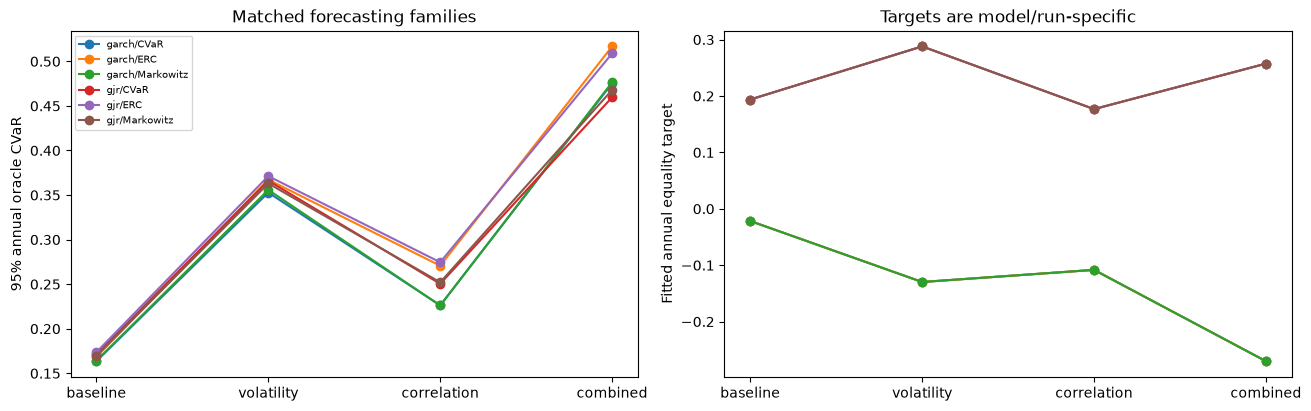

In [4]:
# M5.STRESS.PLOT — Plot risk alongside changing targets
# Inputs: stress_results
# Created: stress_plot
stress_plot,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
view=stress_results[(stress_results.confidence==.95)&(stress_results.forecast_family==stress_results.oracle)]
for (oracle,strategy),group in view.groupby(['oracle','strategy']):
    axes[0].plot(group.stress,group.oracle_cvar,marker='o',label=f'{oracle}/{strategy}')
    axes[1].plot(group.stress,group.fitted_target,marker='o',label=f'{oracle}/{strategy}')
axes[0].set(ylabel='95% annual oracle CVaR',title='Matched forecasting families')
axes[1].set(ylabel='Fitted annual equality target',title='Targets are model/run-specific')
axes[0].legend(fontsize=7)
plt.show()


### Save the stress comparison and run links

Every row retains the underlying run ID for its configuration, diagnostics and weights.

**Inputs:** stress_results, design, figure.  
**Created / outputs:** study artifacts.  
**Canonical implementation:** `annual.studies.save_study`.

In [5]:
# M5.STRESS.SAVE — Save the stress comparison and run links
# Inputs: stress_results, design, figure
# Created: study artifacts
path=study_directory(root,'stress-comparison')
save_study(path,{'comparisons':stress_results,'design':stress_design},{'profile':cfg['status'],'interpretation':'single-history conditional comparisons; not M7 replicated inference'})
stress_plot.savefig(path/'stress.png',dpi=150,bbox_inches='tight')
print(path)


/Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/results/m05-stress-comparison-20261127T163552-703a64d7
